# Picking de fases P/S aprendido en trazas STEAD

**Pregunta:** ¿Qué cambia cuando un picker neuronal de tres componentes reemplaza una regla STA/LTA fija, y qué permiten concluir estas trazas seleccionadas?

**Nivel 3 · Sismología y evaluación de modelos · 60–90 min**

Prerrequisitos: QC de formas de onda y primeras llegadas; evaluación retenida y métricas por clase.

## Objetivos

- Reconstruir la entrada ENZ normalizada, la salida N/P/S y las reglas fijas de umbral y separación de fases.
- Ejecutar localmente los bytes ONNX publicados para cada traza QC-válida del conjunto de visualización preseleccionado de 24 registros.
- Comparar M13 aprendido y el baseline STA/LTA M08 sobre las mismas entradas con referencia de analista.
- Distinguir el subconjunto descriptivo de 23 trazas del benchmark de prueba congelado de 6.000 trazas.

## Preparación

Usa el entorno de investigación fijado por el repositorio. La inferencia ONNX se ejecuta en `.venv-pipeline`, que contiene el runtime bloqueado del modelo. Desde la raíz del repositorio, instala los paquetes del notebook con:

```text
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8 pandas==2.2.3
```

Define `CAOS_TEMP_ROOT` como directorio temporal escribible antes de ejecutar. El análisis derivado se guarda allí; las trazas descargadas o generadas no se escriben en el repositorio.

In [1]:
# Report pinned runtime and verify selected case counts before analysis.
from importlib.metadata import version
from pathlib import Path
import json, os, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
assets = root / "data/derived/phase/browser-assets/stead"
manifest = json.loads((assets / "manifest.json").read_text(encoding="utf-8"))
benchmark = json.loads((assets / "benchmark.json").read_text(encoding="utf-8"))
print("Versiones del entorno:", {name: version(name) for name in ["numpy", "scipy", "matplotlib", "pandas"]})
print("Recursos:", len(manifest["records"]), "seleccionados;",
      sum(row["status"] == "qc-valid" for row in manifest["records"]), "válidos;",
      sum(row["status"] == "qc-rejected" for row in manifest["records"]), "rechazados")
print("Benchmark congelado:", benchmark["selected"], "seleccionados;", benchmark["valid"],
      "válidos por QC;", benchmark["qc_rejected"], "rechazados por QC")
assert manifest["browser_parity_verified"] is False
assert manifest["selection"]["selected_before_heldout_scoring"] is True
assert benchmark["metrics_include_qc_failures_as_unpicked"] is True

Versiones del entorno: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8', 'pandas': '3.0.6'}
Recursos: 24 seleccionados; 23 válidos; 1 rechazados
Benchmark congelado: 6000 seleccionados; 5926 válidos por QC; 74 rechazados por QC


## Datos

El paquete del navegador contiene 24 registros seleccionados antes de puntuar la prueba: 23 formas de onda válidas y una traza de ruido rechazada por QC. La fila rechazada no incluye forma de onda y nunca se envía al modelo. Las trazas válidas permiten inspeccionar señales medidas y modos de fallo, pero el subconjunto seleccionado no es representativo ni permite afirmar precisión poblacional.

El benchmark congelado independiente cubre 6.000 trazas de prueba STEAD disjuntas por evento y estación; sus métricas M08/M13 cuentan los fallos QC como no seleccionados. Esta lección recalcula el subconjunto con ONNX Runtime CPU y muestra las métricas agregadas del benchmark al lado. El recibo separado del 2026-10-27 compara este mismo ONNX congelado en CPU y en la ruta WASM del navegador para las 23 trazas válidas; este notebook no repite la comparación separada con el oráculo privado PyTorch ni reescribe el marcador de exportación del manifiesto.

## Método

Cada registro de 60 s se muestrea a 100 Hz y se almacena como tres arreglos componente-principal en orden **E, N, Z**. Para los conteos crudos $x_c$, la transformación es $z_c=(x_c-\operatorname{mean}_{64}(x_c))/\max_t|x_c-\operatorname{mean}_{64}(x_c)|$. El modelo transforma $z\in\mathbb{R}^{1	imes3	imes6000}$ en puntajes por muestra $q\in[0,1]^{1	imes3	imes6000}$ ordenados **N, P, S**. Un pick es el máximo global de su fase si alcanza 0,8; S se suprime si ocurre a menos de 0,4 s de P. Son umbrales de decisión, no incertidumbre calibrada.

El análisis verifica manifiesto, modelo y hashes de las trazas; luego aplica las implementaciones publicadas de M08 y M13 a formas de onda idénticas. La evaluación emparejada usa la tolerancia congelada de ±0,5 s. Una llegada de analista es una referencia, no una verdad geológica; el orden de activación STA/LTA también puede confundir S con otro inicio.

In [2]:
# Ejecuta el proceso local M08/M13 con versiones fijadas. Los arreglos derivados quedan en CAOS_TEMP_ROOT.
work = Path(os.environ["CAOS_TEMP_ROOT"]) / "m13-display-subset"
work.mkdir(parents=True, exist_ok=True)
result_path = work / "analysis.json"
engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engines = [engine_root / ".venv-pipeline/Scripts/python.exe", engine_root / ".venv-pipeline/bin/python"]
engine = next((candidate for candidate in engines if candidate.is_file()), None)
if engine is None:
    raise RuntimeError("Se requiere el intérprete fijado .venv-pipeline con onnxruntime y torch")
run = subprocess.run(
    [str(engine), str(engine_root / "data-pipeline/stead_phase_browser_subset.py"),
     "--assets", str(assets), "--output", str(result_path)],
    cwd=engine_root, capture_output=True, text=True, timeout=240,
)
if run.returncode:
    raise RuntimeError("Falló el proceso M13 del subconjunto: " + run.stderr[-3000:])
analysis = json.loads(result_path.read_text(encoding="utf-8"))
assert analysis["schema"] == "caos.m13-browser-display-subset-analysis.v1"
assert (analysis["selected_count"], analysis["qc_valid_count"], analysis["qc_rejected_count"]) == (24, 23, 1)
assert analysis["status"].startswith("recomputed-23-trace-descriptive-subset")
print(run.stdout)
print("SHA-256 del manifiesto:", analysis["manifest_sha256"])
print("SHA-256 del modelo:", analysis["model_sha256"])

{
  "status": "recomputed-23-trace-descriptive-subset; not full benchmark or browser parity",
  "selected_count": 24,
  "qc_valid_count": 23,
  "qc_rejected_count": 1,
  "noise_valid_count": 7,
  "manifest_sha256": "d4d2b5b1a98d3a7a2077baab7750c8a96e4b5152b6930e4a09ae4bdc97db8394",
  "model_sha256": "4e5962ed0a9037e545991c218ae770ae7aff2c01f1e6a919c338705780ce5f4c",
  "reference_runtime": {
    "name": "onnxruntime",
    "version": "1.30.0",
    "provider": "CPUExecutionProvider"
  },
  "display_subset_metrics": {
    "M08": {
      "P": {
        "reference_count": 16,
        "correct_within_0p5s": 2,
        "missed": 0,
        "outside_tolerance": 14,
        "false_without_reference": 7,
        "precision_at_0p5s": 0.08695652173913043,
        "recall_at_0p5s": 0.125,
        "f1_at_0p5s": 0.10256410256410256,
        "valid_noise_false_pick_rate": 1.0,
        "picked_reference_count": 16,
        "timing_bias_median_s": -4.025,
        "timing_absolute_median_s": 4.025,
      

## Estado del arte

PhaseNet popularizó curvas de probabilidad por muestra para llegadas P y S a partir de formas de onda de tres componentes, mientras que STEAD ofrece un conjunto amplio de trazas sísmicas y de ruido con picks de analistas. El checkpoint mostrado aquí fue entrenado independientemente y pertenece a la familia PhaseNet; no es el checkpoint oficial PhaseNet. Comparar ambos algoritmos con la misma entrada y separar evidencia poblacional retenida por evento/estación del conjunto de visualización seleccionado evita confundir una curva atractiva con generalización demostrada.

## Resultados

Ejecuta las celdas para inspeccionar formas de onda reales, salidas de los detectores, métricas por cohorte y residuales por traza. Interpreta las diferencias junto con el número de casos seleccionados y la decisión QC. El benchmark congelado es el único resultado poblacional mostrado aquí.

### Inspeccionar un registro medido

El panel superior superpone los tres componentes medidos y normalizados. Las líneas verticales distinguen referencias de analistas, predicciones M13 y activaciones M08. El panel inferior muestra las curvas reales N/P/S emitidas por el modelo ONNX publicado. Los tiempos de analista solo se usan para visualización y evaluación, nunca por los detectores.

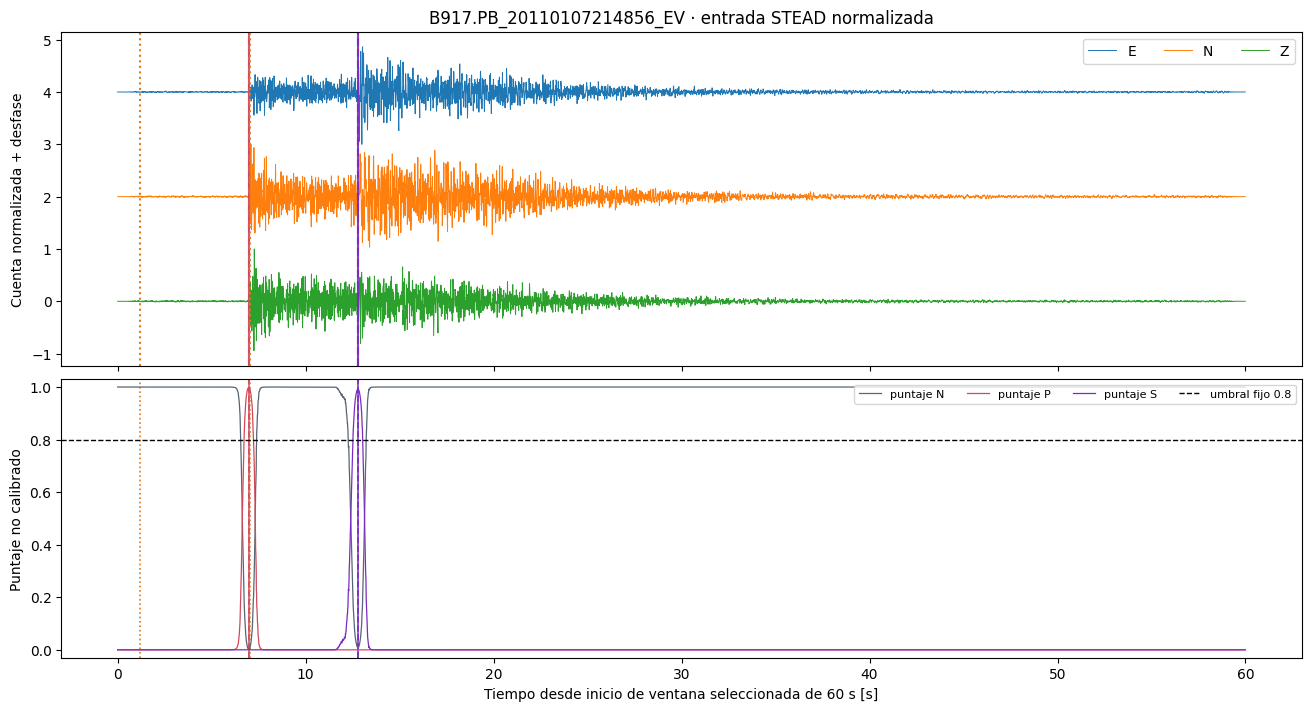

Referencias de analista (no verdad geológica): 7.0 12.77 s
Picks M13: 6.99 12.780000000000001 s; picks M08: 1.19 7.0200000000000005 s


In [3]:
# Plot measured components and the exact ONNX probability curves with reference and detector picks.
example = analysis["example"]
wave = np.asarray(example["waveform_enz"], dtype=float)
prob = np.asarray(example["probabilities_nps"], dtype=float)
time_s = np.arange(len(wave)) / 100
fig, (ax_wave, ax_prob) = plt.subplots(2, 1, figsize=(13, 7), sharex=True,
                                       gridspec_kw={"height_ratios": [1.2, 1]}, constrained_layout=True)
for index, name in enumerate(("E", "N", "Z")):
    ax_wave.plot(time_s, wave[:, index] + 2 * (2 - index), lw=0.7, label=name)
ax_wave.set_ylabel("Cuenta normalizada + desfase")
ax_wave.set_title(f"{example['trace_id']} · entrada STEAD normalizada")
ax_wave.legend(ncol=3, loc="upper right")
for phase, color in (("P", "#d1495b"), ("S", "#7b2cbf")):
    reference = example[f"analyst_{phase.lower()}_s"]
    learned = example[f"m13_{phase.lower()}_s"]
    classical = example[f"m08_{phase.lower()}_s"]
    if reference is not None:
        ax_wave.axvline(reference, color=color, ls="--", lw=1.5, label=f"analista {phase}")
        ax_prob.axvline(reference, color=color, ls="--", lw=1.2)
    if learned is not None:
        ax_wave.axvline(learned, color=color, ls="-", lw=1.5, alpha=0.9, label=f"M13 {phase}")
        ax_prob.axvline(learned, color=color, ls="-", lw=1.2, alpha=0.9)
    if classical is not None:
        ax_wave.axvline(classical, color="#e07a1f", ls=":", lw=1.5, label=f"M08 {phase}")
        ax_prob.axvline(classical, color="#e07a1f", ls=":", lw=1.2)
for index, name, color in ((0, "N", "#576574"), (1, "P", "#d1495b"), (2, "S", "#7b2cbf")):
    ax_prob.plot(time_s, prob[:, index], lw=0.9, label=f"puntaje {name}", color=color)
ax_prob.axhline(0.8, color="black", ls="--", lw=1, label="umbral fijo 0.8")
ax_prob.set(xlabel="Tiempo desde inicio de ventana seleccionada de 60 s [s]", ylabel="Puntaje no calibrado", ylim=(-0.03, 1.03))
ax_prob.legend(ncol=4, loc="upper right", fontsize=8)
plt.show()
print("Referencias de analista (no verdad geológica):", example["analyst_p_s"], example["analyst_s_s"], "s")
print("Picks M13:", example["m13_p_s"], example["m13_s_s"], "s; picks M08:", example["m08_p_s"], example["m08_s_s"], "s")

### Comparar cohortes y modos de error

Estos gráficos agrupan las métricas de prueba congelada de 6.000 trazas junto al subconjunto seleccionado de 23 trazas válidas. El panel de falsos picks en ruido contiene 931 casos válidos de ruido en la prueba completa y solo siete aquí. Interpreta la cohorte menor como apoyo para inspeccionar trazas, no como validación de mejora poblacional.

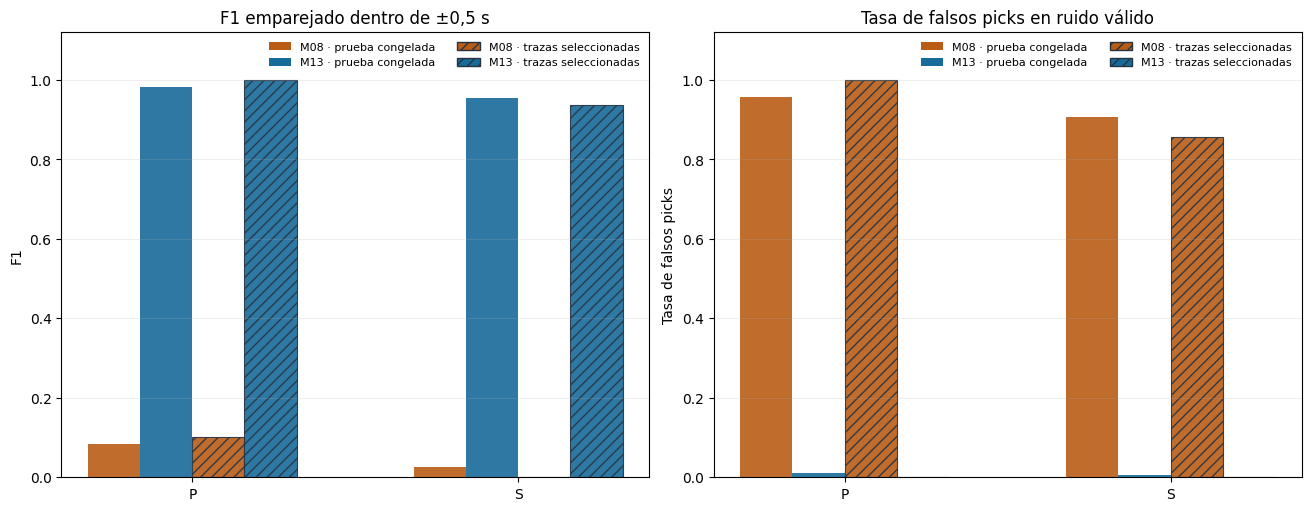

,cohorte,método,F1 P,F1 S,ruido falso P,ruido falso S
0,Prueba congelada (n=6.000),M08,0.083,0.025,0.957,0.908
1,Prueba congelada (n=6.000),M13,0.981,0.955,0.011,0.006
2,Trazas seleccionadas (n=23),M08,0.103,0.000,1.000,0.857
3,Trazas seleccionadas (n=23),M13,1.000,0.938,0.000,0.000


In [4]:
# Compare locked benchmark aggregates with descriptive display-subset metrics.
cohorts = {
    "Prueba congelada (n=6.000)": analysis["locked_6000_test_metrics"],
    "Trazas seleccionadas (n=23)": analysis["display_subset_metrics"],
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
phases = ["P", "S"]
methods = ["M08", "M13"]
colors = {"M08": "#b85c16", "M13": "#176b9a"}
width = 0.16
x = np.arange(2)
for cohort_index, (cohort_name, metrics) in enumerate(cohorts.items()):
    cohort_shift = (cohort_index - 0.5) * 2 * width
    for method_index, method in enumerate(methods):
        shift = cohort_shift + (method_index - 0.5) * width
        f1_values = [metrics[method][phase]["f1_at_0p5s"] for phase in phases]
        false_values = [metrics[method][phase]["valid_noise_false_pick_rate"] for phase in phases]
        style = {} if cohort_index == 0 else {"hatch": "///", "edgecolor": "#263442", "linewidth": 0.8}
        axes[0].bar(x + shift, f1_values, width, color=colors[method], alpha=0.9, **style)
        axes[1].bar(x + shift, false_values, width, color=colors[method], alpha=0.9, **style)
axes[0].set(title="F1 emparejado dentro de ±0,5 s", ylabel="F1", xticks=x, xticklabels=phases, ylim=(0, 1.12))
axes[1].set(title="Tasa de falsos picks en ruido válido", ylabel="Tasa de falsos picks", xticks=x, xticklabels=phases, ylim=(0, 1.12))
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=colors["M08"], label="M08 · prueba congelada"),
    Patch(facecolor=colors["M13"], label="M13 · prueba congelada"),
    Patch(facecolor=colors["M08"], hatch="///", edgecolor="#263442", label="M08 · trazas seleccionadas"),
    Patch(facecolor=colors["M13"], hatch="///", edgecolor="#263442", label="M13 · trazas seleccionadas"),
]
for axis in axes:
    axis.grid(axis="y", alpha=0.2)
    axis.legend(handles=legend_handles, fontsize=8, frameon=False, ncol=2, loc="upper right")
plt.show()

rows = []
for cohort_name, metrics in cohorts.items():
    for method in methods:
        rows.append({"cohorte": cohort_name, "método": method,
                     "F1 P": metrics[method]["P"]["f1_at_0p5s"],
                     "F1 S": metrics[method]["S"]["f1_at_0p5s"],
                     "ruido falso P": metrics[method]["P"]["valid_noise_false_pick_rate"],
                     "ruido falso S": metrics[method]["S"]["valid_noise_false_pick_rate"]})
display(pd.DataFrame(rows).round(3))

### Auditar trazas individuales

La tabla expone omisiones, llegadas tempranas/tardías y falsas alarmas de ruido por traza. Los residuales son predicción menos referencia de analista; valores vacíos indican una fase no seleccionada o sin referencia. La ventana de emparejamiento de ±0,5 s es una convención de evaluación, no una afirmación sobre la precisión del analista.

In [5]:
# Calculate prediction-minus-reference residuals for each selected trace.
trace_rows = pd.DataFrame(analysis["traces"])
for phase in ("P", "S"):
    trace_rows[f"Residual M13 {phase} [s]"] = trace_rows[f"m13_{phase.lower()}_s"] - trace_rows[f"analyst_{phase.lower()}_s"]
    trace_rows[f"Residual M08 {phase} [s]"] = trace_rows[f"m08_{phase.lower()}_s"] - trace_rows[f"analyst_{phase.lower()}_s"]
display(trace_rows[["trace_id", "category", "analyst_p_s", "m08_p_s", "m13_p_s",
                     "Residual M08 P [s]", "Residual M13 P [s]", "analyst_s_s", "m08_s_s", "m13_s_s",
                     "Residual M08 S [s]", "Residual M13 S [s]"]].round(2))

,trace_id,category,analyst_p_s,m08_p_s,m13_p_s,Residual M08 P [s],Residual M13 P [s],analyst_s_s,m08_s_s,m13_s_s,Residual M08 S [s],Residual M13 S [s]
0,B917.PB_20110107214856_EV,earthquake_local,7.0,1.19,6.99,-5.81,-0.01,12.77,7.02,12.78,-5.75,0.01
1,B093.PB_20111211064029_EV,earthquake_local,7.0,1.19,7.02,-5.81,0.02,9.32,7.02,9.35,-2.30,0.03
2,BBGB.NC_20110929163129_EV,earthquake_local,9.0,3.00,8.99,-6.00,-0.01,12.60,9.00,12.58,-3.60,-0.02
3,BBGB.NC_20110309162307_EV,earthquake_local,5.0,1.59,5.00,-3.41,0.00,8.91,3.42,9.12,-5.49,0.21
4,BBR.CI_20160306010500_EV,earthquake_local,4.0,1.19,4.00,-2.81,0.00,13.43,4.07,13.82,-9.36,0.39
5,LMR2.CI_20130325173024_EV,earthquake_local,5.0,1.22,4.96,-3.78,-0.04,10.88,1.67,10.82,-9.21,-0.06
6,BDM.BK_20160112043452_EV,earthquake_local,7.0,1.19,6.99,-5.81,-0.01,11.08,7.03,11.20,-4.05,0.12
7,SAO.BK_20131207235848_EV,earthquake_local,7.0,1.23,7.00,-5.77,0.00,10.55,1.70,10.62,-8.85,0.07
8,CRY.AZ_20120529154839_EV,earthquake_local,6.0,1.73,6.00,-4.27,0.00,9.34,4.62,9.43,-4.72,0.09
9,CRY.AZ_20160919195008_EV,earthquake_local,9.0,1.19,9.02,-7.81,0.02,14.16,9.03,14.10,-5.13,-0.06


## Resumen

- Las 23 trazas válidas seleccionadas se procesan con el modelo ONNX publicado y el detector M08; sus métricas son descriptivas e incluyen solo siete trazas válidas de ruido.
- Usa la prueba congelada de 6.000 trazas disjuntas por evento/estación para conclusiones del benchmark; los fallos QC cuentan como no seleccionados y los falsos picks de ruido se informan por separado.
- Los picks de analista son referencias, no verdad del subsuelo. Los puntajes no están calibrados; los umbrales pueden abstenerse o fallar.
- Una ejecución local separada de ONNX CPU frente a WASM del navegador pasó para las 23 trazas válidas: diferencia máxima de probabilidad 5,07e-6 y picks máximos P/S en muestras idénticas. Esto valida paridad de runtime del ONNX congelado, no el modelo de forma independiente frente a PyTorch. Consulta `docs/validation/m13-browser-population-parity-2026-10-27.md`. El valor `browser_parity_verified=false` del manifiesto conserva el estado de exportación registrado al crear los activos.
- Reproduce con `python scripts/run_notebooks.py --only notebooks/es/06-seismology/04-m13-learned-phase-picking.ipynb` tras definir `CAOS_TEMP_ROOT` y preparar `.venv-pipeline`. Esta lección no reemplaza la custodia completa, la paridad ni la aceptación del release.

## Referencias

1. Zhu, W. y Beroza, G. C. (2019). PhaseNet: un método neuronal profundo para picking de tiempos de llegada sísmica. *Geophysical Journal International*. https://doi.org/10.1093/gji/ggy423
2. Mousavi, S. M. et al. (2019). STEAD: conjunto de datos de formas de onda sísmicas y metadatos asociados. *IEEE Access*. https://doi.org/10.1109/ACCESS.2019.2947848